In [1]:
import sympy
from sympy import symbols, solve
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, least_squares
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

In [2]:
r1,r2,l1,l2,l3,l4 = symbols('r1 r2 l1 l2 l3 l4')
t=symbols('t')
theta1,theta2 = dynamicsymbols('theta1 theta2') 
alpha3,alpha4 = theta1, theta2
alpha1,alpha2,alpha5,alpha6 = dynamicsymbols('alpha1 alpha2 alpha5 alpha6')

f1 = 0.5
f2 = 0.5

paramsfront = {r1: 0.111, r2:0.153}

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', [alpha1, N.z])
B = N.orientnew('B', 'Axis', [alpha2, A.z])
C = N.orientnew('C', 'Axis', [alpha3, N.z])
D = N.orientnew('D', 'Axis', [alpha4, C.z])
E = N.orientnew('E', 'Axis', [alpha5, C.z])
F = N.orientnew('F', 'Axis', [alpha6, E.z])

r1 = r1*C.x
r2 = r2*D.x
l1 = l1*A.x
l2 = l2*B.x
l3 = l3*E.x
l4 = l4*F.x

dx = 48*np.cos(np.radians(45))*N.x
dy = -48*np.sin(np.radians(45))*N.y

eq1 = l1 + l2 + (1-f1)*r1 + f2*r2 - l4 - l3 - dx - dy
eq2 = r1 + f2*r2 - l4 - l3

P = dx + dy + r1 + r2

eqkin=sympy.Matrix([eq1.dot(N.x), eq1.dot(N.y), eq2.dot(N.x), eq2.dot(N.y)])
eqkin_fun=sympy.lambdify([theta1, theta2], eqkin)
myfun = lambda x: eqkin_fun(x[0], x[1], x[2])

## Optimización de `l1`, `l2`, `l3` (y `l4`) barriendo `f1` y `f2`: patas FR y BR

Del modelo simbólico de arriba, restando `eq2` de `eq1`, el mecanismo queda así (todos los ángulos son **absolutos**, como en los marcos `orientnew` de arriba):

- `B` (actuador del RR 1) está en el origen; el pivote `O` de `r1` está en `d = (dx, -dy)`, con `dx` y `dy` iguales o mayores que los de la celda simbólica (`48·cos45° = 33.9 mm`, son los mínimos posibles).
- **RR 1** (`l1`, `l2`): base en `B`, extremo en `Q1 = O + f1·r1`.
- **RR 2** (`l3`, `l4`): base en `O`, extremo en `Q2 = O + r1 + f2·r2`.
- `P = O + r1 + r2` es el extremo de la pata.

Un RR de eslabones `a`, `b` alcanza un punto a distancia `D` solo si `|a - b| <= D <= a + b` (con `MARGEN` respecto al brazo estirado).

**`l4` no es una variable**: es la distancia desde la punta de `l3` hasta el punto `f2·r2` en la pose de referencia (centro del rango), con `l3` apuntando a un ángulo `a3` en esa pose. Quedan como variables `l1`, `l2`, `l3`, `dx`, `dy` y `a3`. Con `L3_ANG = None` el ángulo `a3` también se optimiza; con un número (en radianes) queda fijo.

**No pueden superponerse elementos.** En cada pose se calcula la cinemática inversa de los dos RR y se exige una distancia mayor que `CLEARANCE` entre todos los pares de eslabones que no comparten articulación (`r1`, `r2`, `l1`, `l2`, `l3`, `l4`). Para el RR 1 se prueban las dos ramas del codo y se usa la mejor.

Para cada par `(f1, f2)` entre 0 y 0.5 se minimiza con evolución diferencial

`costo = W_L4·l4 + W_L·(l1+l2+l3) + W_D·(aumento de dx y dy) + W_RANGO·(1 - cobertura del rango ampliado) + penalización si el rango nominal no queda cubierto sin colisión`

- **Rango nominal**: caja de `theta1`, `theta2` que sale del CSV (tibia y metatarso de la pata). Debe cubrirse al 100 % sin colisiones.
- **Rango ampliado**: el nominal más `AMPLIAR_DEG` por lado. La fracción de poses de esta caja que ambos RR alcanzan sin colisión mide el rango de movimiento de `P`.

Con `f` cercano a 0 el RR casi no tiene brazo de palanca sobre el eslabón, así que el mapa lo muestra pero la selección solo considera `f >= F_MIN`.

El mismo código sirve para las dos patas: `preparar_pata` arma el problema de una pata (longitudes y columnas del CSV), `optimizar_pata` hace el barrido y `graficar_mapas`, `graficar_diseno` y `animar` muestran el resultado.

In [3]:
import time
from scipy.optimize import differential_evolution
from scipy.spatial import ConvexHull
from IPython.display import Image, display

# --- Parametros comunes a las dos patas (editables) ---
CSV_PATH = Path("leg_motor_angles_one_cycle.csv")
X_FORWARD = True                   # igual que Mecanismo.ipynb: x del mecanismo hacia adelante
DX0 = DY0 = 0.048 * np.cos(np.radians(45))   # [m] minimos de dx y dy (valores de la celda simbolica); O = (dx, -dy)
D_EXTRA = 0.05                     # [m] cuanto pueden crecer dx y dy sobre su minimo
L3_ANG = None                      # angulo absoluto de l3 en la pose de referencia [rad]; None = se optimiza
F_VALS = np.round(np.arange(0, 0.5001, 0.1), 2)   # barrido de f1 y f2 (0.05 lo afina pero tarda ~4x; ~6 min por pata con 0.1)
AMPLIAR_DEG = 20.0                 # ampliacion del rango (por lado) para medir el rango de P
MARGEN = 0.05                      # holgura respecto al brazo estirado
CLEARANCE = 0.005                  # [m] separacion minima entre eslabones que no comparten articulacion
F_MIN = 0.2                        # f minimo admisible para elegir el diseno
W_L4, W_L, W_RANGO, W_D = 3.0, 1.0, 2.0, 1.0   # pesos (l4 / 0.1 m, longitudes / 0.3 m, dx+dy extra / 0.05 m)
N_NOM, N_EXT = 9, 13               # puntos por eje de la rejilla nominal / ampliada
DE_KW = dict(maxiter=50, popsize=8, tol=1e-8, polish=False, seed=1)

u = lambda a: np.stack([np.cos(a), np.sin(a)], axis=-1)
colores = ['tab:blue', 'tab:blue', 'tab:orange', 'tab:orange', 'tab:red', 'tab:red']
etiq = ['r1', 'r2', 'l1', 'l2', 'l3', 'l4']

# --- Geometria de segmentos (para la no superposicion) ---
def pto_seg(p, a, b):
    ab = b - a; t = np.clip(((p - a) * ab).sum(-1) / (ab * ab).sum(-1), 0, 1)
    return np.linalg.norm(p - (a + t[:, None] * ab), axis=-1)

def cruzan(a, b, c, d):
    cr = lambda p, q, r: (q[:, 0] - p[:, 0]) * (r[:, 1] - p[:, 1]) - (q[:, 1] - p[:, 1]) * (r[:, 0] - p[:, 0])
    return (cr(a, b, c) * cr(a, b, d) < 0) & (cr(c, d, a) * cr(c, d, b) < 0)

def dist_seg(a, b, c, d):
    m = np.minimum.reduce([pto_seg(a, c, d), pto_seg(b, c, d), pto_seg(c, a, b), pto_seg(d, a, b)])
    return np.where(cruzan(a, b, c, d), 0.0, m)

# Eslabones: 0 r1, 1 r2, 2 l1, 3 l2, 4 l3, 5 l4. Se excluyen los pares que comparten articulacion
# (r1-r2, l1-l2, l3-l4, r1-l3 en O, r2-l4 en Q2, r1-l2 en Q1).
PARES = [(0, 2), (0, 5), (1, 2), (1, 3), (1, 4), (2, 4), (2, 5), (3, 4), (3, 5)]

def ik(base, tip, a, b, rama):
    v = tip - base; D = np.linalg.norm(v, axis=-1)
    c = np.clip((a**2 + D**2 - b**2) / (2 * a * np.maximum(D, 1e-9)), -1, 1)
    return base + a * u(np.arctan2(v[..., 1], v[..., 0]) + rama * np.arccos(c))

def rejilla(rng, n):
    a, b = np.meshgrid(*[np.linspace(*r, n) for r in rng], indexing='ij')
    return a.ravel(), b.ravel()

### Problema de una pata

`preparar_pata` lee el rango de `theta1`, `theta2` del CSV (orientación absoluta de la tibia y del metatarso, convención MuJoCo → plano) y arma las rejillas de poses. `evaluar` devuelve qué poses alcanzan los dos RR sin superposición y `costo` es la función que minimiza la evolución diferencial.

In [4]:
def preparar_pata(nombre, cols, R1, R2, l_max):
    # cols: columnas del CSV para theta1 (r1) y theta2 (r2); SUPUESTO: tibia y metatarso, orientacion absoluta
    df = pd.read_csv(CSV_PATH)
    ang = -np.pi / 2 + (-1 if X_FORWARD else 1) * np.deg2rad(df[list(cols)].to_numpy())
    rng_nom = [(ang[:, k].min(), ang[:, k].max()) for k in range(2)]
    rng_ext = [(a - np.radians(AMPLIAR_DEG), b + np.radians(AMPLIAR_DEG)) for a, b in rng_nom]
    print(f"[{nombre}] Rango nominal  theta1, theta2 [deg]:", np.rad2deg(rng_nom).round(1).tolist())
    print(f"[{nombre}] Rango ampliado theta1, theta2 [deg]:", np.rad2deg(rng_ext).round(1).tolist())
    return dict(nombre=nombre, R1=R1, R2=R2, t=df['time_s'].to_numpy(), ang=ang,
                ref=np.array([np.mean(r) for r in rng_nom]),          # pose de referencia (centro del rango)
                rng_nom=rng_nom, g_nom=rejilla(rng_nom, N_NOM), g_ext=rejilla(rng_ext, N_EXT),
                bounds=[(0.01, l_max)] * 3 + [(DX0, DX0 + D_EXTRA), (DY0, DY0 + D_EXTRA), (-np.pi, np.pi)])

def l4_de(pt, l3, f2, a3):
    # distancia de la punta de l3 (a a3 desde O) al punto f2 de r2 en la pose de referencia
    return np.linalg.norm(l3 * u(a3) - (pt['R1'] * u(pt['ref'][0]) + f2 * pt['R2'] * u(pt['ref'][1])))

def rama_rr2(pt, l3, l4, f2, a3):
    # rama del codo del RR 2 con la que l3 queda a a3 en la pose de referencia (se mantiene en todo el rango)
    v = pt['R1'] * u(pt['ref'][0]) + f2 * pt['R2'] * u(pt['ref'][1]); D = np.linalg.norm(v)
    c = np.clip((l3**2 + D**2 - l4**2) / (2 * l3 * max(D, 1e-9)), -1, 1)
    a0 = np.arctan2(v[1], v[0]); w = lambda x: abs(np.angle(np.exp(1j * x)))
    return +1 if w(a0 + np.arccos(c) - a3) <= w(a0 - np.arccos(c) - a3) else -1

def evaluar(pt, x, f1, f2, g, b1, detalle=False):
    # x = (l1, l2, l3, dx, dy, a3); devuelve (poses OK, l4)
    R1, R2 = pt['R1'], pt['R2']
    l1_, l2_, l3_, dx, dy, a3 = x
    a3 = a3 if L3_ANG is None else L3_ANG
    l4_ = l4_de(pt, l3_, f2, a3); th1, th2 = g; n = len(th1)
    O = np.broadcast_to(np.array([dx, -dy]), (n, 2)); B = np.zeros((n, 2))
    J = O + R1 * u(th1); P = J + R2 * u(th2)
    Q1 = O + f1 * R1 * u(th1); Q2 = J + f2 * R2 * u(th2)
    D1 = np.linalg.norm(Q1, axis=1); D2 = np.linalg.norm(Q2 - O, axis=1)
    alcanza = ((D1 >= abs(l1_ - l2_)) & (D1 <= (l1_ + l2_) / (1 + MARGEN))
               & (D2 >= abs(l3_ - l4_)) & (D2 <= (l3_ + l4_) / (1 + MARGEN)))
    K1 = ik(B, Q1, l1_, l2_, b1); K2 = ik(O, Q2, l3_, l4_, rama_rr2(pt, l3_, l4_, f2, a3))
    S = [(O, J), (J, P), (B, K1), (K1, Q1), (O, K2), (K2, Q2)]
    A0 = np.stack([s[0] for s in S]); A1 = np.stack([s[1] for s in S])      # (6, n, 2): inicio y fin de cada eslabon
    ii, jj = [list(k) for k in zip(*PARES)]
    d = dist_seg(A0[ii].reshape(-1, 2), A1[ii].reshape(-1, 2), A0[jj].reshape(-1, 2), A1[jj].reshape(-1, 2))
    libre = (d.reshape(len(PARES), n) > CLEARANCE).all(axis=0)
    if detalle:
        return alcanza, libre, l4_, S
    return alcanza & libre, l4_

def costo(x, pt, f1, f2):
    mejor = np.inf
    base = (W_L4 * l4_de(pt, x[2], f2, x[5] if L3_ANG is None else L3_ANG) / 0.1 + W_L * (x[0] + x[1] + x[2]) / 0.3
            + W_D * (x[3] - DX0 + x[4] - DY0) / 0.05)
    for b1 in (+1, -1):
        ok_n, _ = evaluar(pt, x, f1, f2, pt['g_nom'], b1)
        if ok_n.all():                       # el rango ampliado solo se evalua si el nominal ya esta cubierto
            ok_e, _ = evaluar(pt, x, f1, f2, pt['g_ext'], b1)
            c = base + W_RANGO * (1 - ok_e.mean())
        else:
            c = base + W_RANGO + 50 * (1 - ok_n.mean())
        mejor = min(mejor, c)
    return mejor

### Barrido de `f1` y `f2`

`optimizar_pata` resuelve la optimización de `(l1, l2, l3, dx, dy, a3)` para cada par `(f1, f2)`. Guarda la solución, `l4`, la rama del RR 1, la cobertura (sin colisión) del rango nominal y del ampliado y el costo, y elige el mejor diseño con `f >= F_MIN` y el rango nominal cubierto al 100 %. Tarda varios minutos por pata.

In [5]:
def optimizar_pata(pt):
    nf = len(F_VALS); shape = (nf, nf)
    X = np.zeros(shape + (6,)); L4 = np.zeros(shape); RAMA = np.ones(shape, int)
    COV_N = np.zeros(shape); COV_E = np.zeros(shape); COSTO = np.zeros(shape)
    t0 = time.time()
    for i, f1 in enumerate(F_VALS):
        for j, f2 in enumerate(F_VALS):
            r = differential_evolution(costo, pt['bounds'], args=(pt, f1, f2), **DE_KW)
            res = []
            for b1 in (+1, -1):
                ok_n, l4_ = evaluar(pt, r.x, f1, f2, pt['g_nom'], b1); ok_e, _ = evaluar(pt, r.x, f1, f2, pt['g_ext'], b1)
                res.append((50 * ok_n.mean() + ok_e.mean(), b1, ok_n.mean(), ok_e.mean(), l4_))
            _, b1, cn, ce, l4_ = max(res)
            X[i, j], L4[i, j], RAMA[i, j], COV_N[i, j], COV_E[i, j], COSTO[i, j] = r.x, l4_, b1, cn, ce, r.fun
    print(f"[{pt['nombre']}] Barrido terminado en {time.time() - t0:.0f} s")

    valido = (F_VALS[:, None] >= F_MIN) & (F_VALS[None, :] >= F_MIN) & (COV_N >= 1.0)
    if not valido.any():
        raise RuntimeError(f"[{pt['nombre']}] Ningun par (f1, f2) cubre el rango nominal sin colision: revisa los parametros")
    ib, jb = np.unravel_index(np.where(valido, COSTO, np.inf).argmin(), shape)
    x_b = X[ib, jb].copy()
    if L3_ANG is not None: x_b[5] = L3_ANG
    res = dict(pt=pt, X=X, L4=L4, RAMA=RAMA, COV_N=COV_N, COV_E=COV_E, COSTO=COSTO, ib=ib, jb=jb,
               f1=F_VALS[ib], f2=F_VALS[jb], x=x_b, b1=RAMA[ib, jb], l4=L4[ib, jb], cov_e=COV_E[ib, jb])
    l1_, l2_, l3_, dx, dy, a3 = x_b
    print(f"[{pt['nombre']}] Mejor: f1 = {res['f1']:.2f}, f2 = {res['f2']:.2f} | l1 = {l1_*1000:.1f}, l2 = {l2_*1000:.1f}, "
          f"l3 = {l3_*1000:.1f}, l4 = {res['l4']*1000:.1f} mm | dx = {dx*1000:.1f}, dy = {dy*1000:.1f} mm | a3 = {np.degrees(a3):.1f} deg"
          f" | rango ampliado cubierto {100*res['cov_e']:.0f} %")
    return res

### Gráficas y animación

- `graficar_mapas`: mapas en `(f2, f1)` de `l4`, `l1+l2+l3`, aumento de `dx+dy`, ángulo de `l3`, cobertura del rango ampliado y costo. La estrella marca el diseño elegido; la zona sombreada es `f < F_MIN`; las celdas con el rango nominal sin cubrir sin colisión quedan en blanco.
- `graficar_diseno`: tabla de eslabones, comprobación del rango nominal y vista del mecanismo en la pose de referencia y en las esquinas del rango, con la nube de `P` sobre la caja ampliada (verde = alcanzable sin colisión).
- `animar`: el mecanismo siguiendo la marcha del CSV (`r1`, `r2` azul; `l1`, `l2` naranja; `l3`, `l4` rojo). Guarda `mecanismo_v2_<pata>.gif` junto al notebook.

In [6]:
def graficar_mapas(res):
    pt = res['pt']; X, L4, COV_N, COV_E, COSTO = (res[k] for k in ('X', 'L4', 'COV_N', 'COV_E', 'COSTO'))
    fig, axs = plt.subplots(2, 3, figsize=(15, 8.5))
    step = F_VALS[1] - F_VALS[0]
    lo, hi = F_VALS[0] - step / 2, F_VALS[-1] + step / 2
    ok_ = COV_N >= 1
    mapas = [
        ('l4 [mm]', np.where(ok_, L4, np.nan) * 1000),
        ('l1 + l2 + l3 [mm]', np.where(ok_, X[:, :, :3].sum(axis=2), np.nan) * 1000),
        ('Aumento de dx + dy sobre el minimo [mm]', np.where(ok_, X[:, :, 3] + X[:, :, 4] - DX0 - DY0, np.nan) * 1000),
        ('Angulo de l3 en la pose de referencia [deg]', np.where(ok_, np.degrees(X[:, :, 5]), np.nan)),
        ('Cobertura del rango ampliado de P [%]', COV_E * 100),
        ('Costo', COSTO),
    ]
    for ax, (ttl, M) in zip(axs.ravel(), mapas):
        im = ax.imshow(M, origin='lower', extent=[lo, hi, lo, hi], aspect='auto', cmap='viridis')
        ax.axvspan(lo, F_MIN - step / 2, color='k', alpha=0.15); ax.axhspan(lo, F_MIN - step / 2, color='k', alpha=0.15)
        ax.plot(res['f2'], res['f1'], 'r*', ms=14)
        ax.set_xlabel('f2'); ax.set_ylabel('f1'); ax.set_title(ttl)
        fig.colorbar(im, ax=ax)
    fig.suptitle(f"Pata {pt['nombre']}")
    plt.tight_layout(); plt.show()


def graficar_diseno(res):
    pt = res['pt']; R1, R2 = pt['R1'], pt['R2']
    f1_b, f2_b, b1_b, x_b = res['f1'], res['f2'], res['b1'], res['x']
    l1_b, l2_b, l3_b, dx_b, dy_b, a3_b = x_b
    tabla = pd.DataFrame([
        ('r1', 'pata (fijo)', R1, None), ('r2', 'pata (fijo)', R2, None),
        ('l1', 'RR 1, acople en r1', l1_b, f1_b), ('l2', 'RR 1, acople en r1', l2_b, f1_b),
        ('l3', f'RR 2, acople en r2 (a {np.degrees(a3_b):.0f} deg en la pose de referencia)', l3_b, f2_b), ('l4', 'RR 2, derivado de l3', res['l4'], f2_b),
        ('dx', 'B -> O en x', dx_b, None), ('dy', 'B -> O en -y', dy_b, None),
    ], columns=['eslabon', 'mecanismo', 'longitud [m]', 'f'])
    tabla['longitud [mm]'] = (tabla['longitud [m]'] * 1000).round(1)
    tabla.insert(0, 'pata', pt['nombre'])
    display(tabla)

    ok_e, _ = evaluar(pt, x_b, f1_b, f2_b, pt['g_ext'], b1_b)
    al_n, li_n, _, _ = evaluar(pt, x_b, f1_b, f2_b, pt['g_nom'], b1_b, detalle=True)
    print(f"[{pt['nombre']}] Rango nominal: alcanzable {100*al_n.mean():.0f} %, sin superposicion {100*li_n.mean():.0f} %. "
          f"Rama del codo del RR 1: {b1_b:+d}")

    def posicion(th1, th2):
        _, _, _, S = evaluar(pt, x_b, f1_b, f2_b, (np.array([th1]), np.array([th2])), b1_b, detalle=True)
        return [(a[0], b[0]) for a, b in S]

    fig, (axa, axb) = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True)
    O_ = np.array([dx_b, -dy_b])
    P_e = O_ + R1 * u(pt['g_ext'][0]) + R2 * u(pt['g_ext'][1])
    axa.scatter(*P_e[~ok_e].T, s=14, c='lightgray', label='fuera de alcance o con colision')
    axa.scatter(*P_e[ok_e].T, s=14, c='tab:green', label='alcanzable sin colision')
    Pn = O_ + R1 * u(pt['g_nom'][0]) + R2 * u(pt['g_nom'][1])
    hv = ConvexHull(Pn).vertices
    axa.plot(*Pn[np.append(hv, hv[0])].T, 'k-', lw=1.5, label='rango nominal')
    rn = pt['rng_nom']
    for ax, poses, alpha in ((axa, [tuple(pt['ref'])], 1.0), (axb, [(a, b) for a in rn[0] for b in rn[1]] + [tuple(pt['ref'])], 0.6)):
        for k, (t1, t2) in enumerate(poses):
            for s, (a, b) in enumerate(posicion(t1, t2)):
                ax.plot([a[0], b[0]], [a[1], b[1]], '-o', color=colores[s], lw=3, ms=4, alpha=alpha, label=etiq[s] if k == 0 else None)
        ax.plot(0, 0, 'ks', ms=9); ax.plot(*O_, 'ks', ms=9)
        ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_xlabel('x [m]')
    axa.set_ylabel('y [m]'); axa.legend(fontsize=8, loc='upper left')
    axa.set_title(f"Pata {pt['nombre']}: f1 = {f1_b:.2f}, f2 = {f2_b:.2f}, rango de P {100*ok_e.mean():.0f} % de la caja ampliada")
    axb.set_title('Esquinas del rango nominal y pose central')
    plt.tight_layout(); plt.show()
    return tabla


def animar(res):
    pt = res['pt']; x_b = res['x']
    al_c, li_c, _, S_c = evaluar(pt, x_b, res['f1'], res['f2'], (pt['ang'][:, 0], pt['ang'][:, 1]), res['b1'], detalle=True)
    print(f"[{pt['nombre']}] Trayectoria del CSV: alcanzable {100*al_c.mean():.0f} %, sin superposicion {100*li_c.mean():.0f} %")
    O_ = np.array([x_b[3], -x_b[4]]); t_csv = pt['t']
    P_tray = S_c[1][1]                                   # extremo P de cada pose
    todos = np.vstack([np.vstack(s) for s in S_c] + [np.zeros((1, 2))])
    pad = 0.03
    fig, ax = plt.subplots(figsize=(6, 7))
    def dibujar(i):
        ax.cla(); ax.set_aspect('equal'); ax.grid(alpha=0.3)
        ax.set_xlim(todos[:, 0].min() - pad, todos[:, 0].max() + pad); ax.set_ylim(todos[:, 1].min() - pad, todos[:, 1].max() + pad)
        ax.plot(*P_tray[:i + 1].T, color='gray', lw=1, alpha=0.6)                 # estela de P
        for s, (a, b) in enumerate(S_c):
            ax.plot([a[i, 0], b[i, 0]], [a[i, 1], b[i, 1]], '-o', color=colores[s], lw=3, ms=5)
        ax.plot(0, 0, 'ks', ms=9); ax.plot(*O_, 'ks', ms=9)
        estado = '' if (al_c[i] and li_c[i]) else '  (fuera de alcance o superpuesto)'
        ax.set_title(f"Pata {pt['nombre']}: t = {t_csv[i]:.2f} s{estado}"); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
    ani = FuncAnimation(fig, dibujar, frames=len(t_csv), interval=60, repeat=True)
    gif = f"mecanismo_v2_{pt['nombre'].lower()}.gif"
    ani.save(gif, writer=PillowWriter(fps=20))
    plt.close(fig)
    display(Image(filename=gif))

## Pata FR

Longitudes de la pata delantera: `r1 = 0.111` (tibia) y `r2 = 0.153` (metatarso), `paramsfront` de arriba. Columnas `fr_knee_motor` y `fr_ankle_motor` del CSV.

In [7]:
pt_fr = preparar_pata('FR', ('fr_knee_motor', 'fr_ankle_motor'), R1=0.111, R2=0.153, l_max=0.30)
res_fr = optimizar_pata(pt_fr)

[FR] Rango nominal  theta1, theta2 [deg]: [[-39.0, -18.2], [-181.8, -96.5]]
[FR] Rango ampliado theta1, theta2 [deg]: [[-59.0, 1.8], [-201.8, -76.5]]


[FR] Barrido terminado en 152 s
[FR] Mejor: f1 = 0.20, f2 = 0.20 | l1 = 52.6, l2 = 26.5, l3 = 39.6, l4 = 106.3 mm | dx = 35.3, dy = 34.1 mm | a3 = -126.6 deg | rango ampliado cubierto 87 %


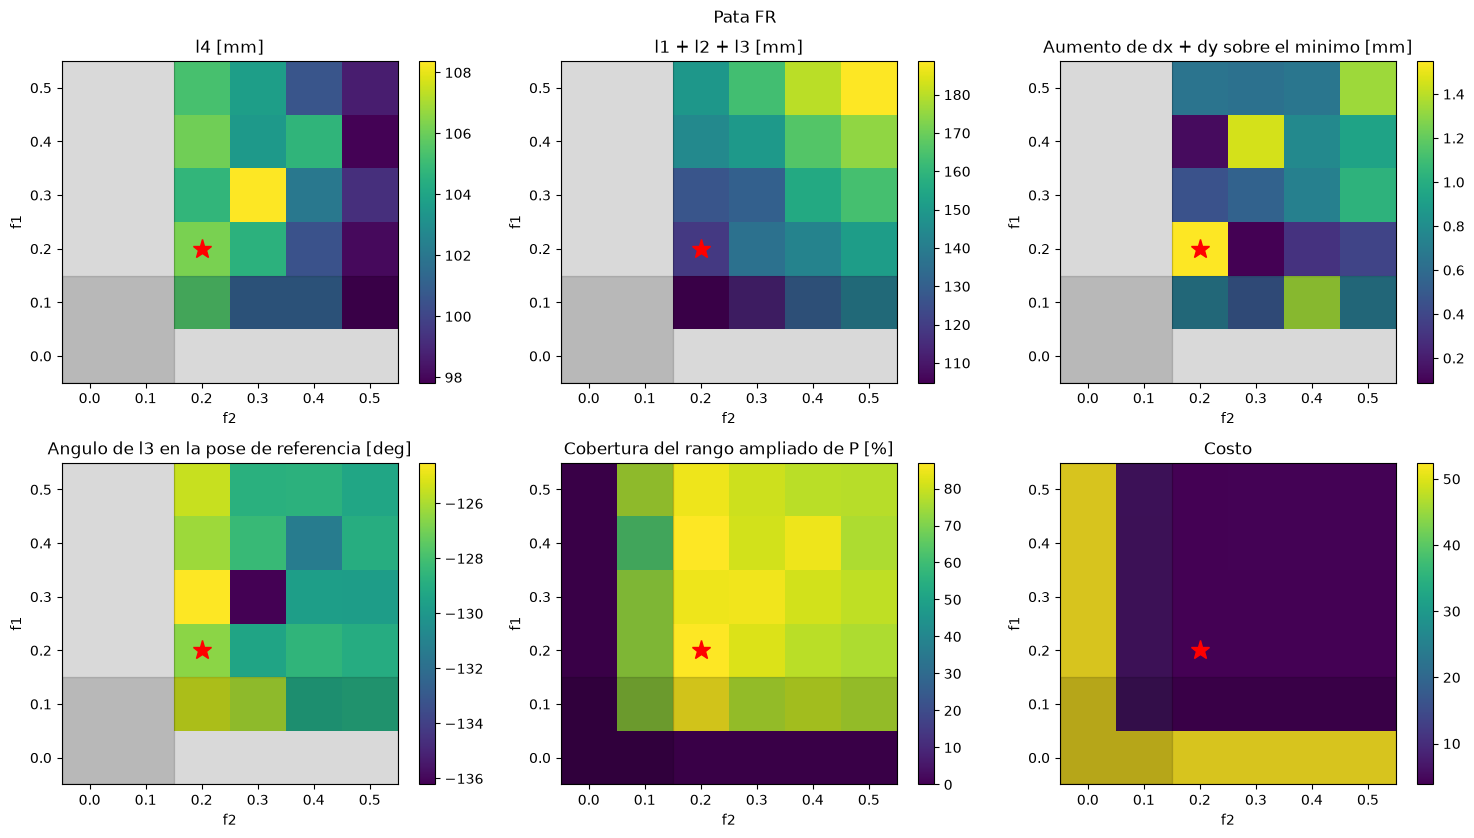

In [8]:
graficar_mapas(res_fr)

,pata,eslabon,mecanismo,longitud [m],f,longitud [mm]
0,FR,r1,pata (fijo),0.111000,NaN,111.0
1,FR,r2,pata (fijo),0.153000,NaN,153.0
2,FR,l1,"RR 1, acople en r1",0.052560,0.2,52.6
3,FR,l2,"RR 1, acople en r1",0.026501,0.2,26.5
4,FR,l3,"RR 2, acople en r2 (a -127 deg en la pose de r...",0.039620,0.2,39.6
5,FR,l4,"RR 2, derivado de l3",0.106252,0.2,106.3
6,FR,dx,B -> O en x,0.035330,NaN,35.3
7,FR,dy,B -> O en -y,0.034103,NaN,34.1


[FR] Rango nominal: alcanzable 100 %, sin superposicion 100 %. Rama del codo del RR 1: +1


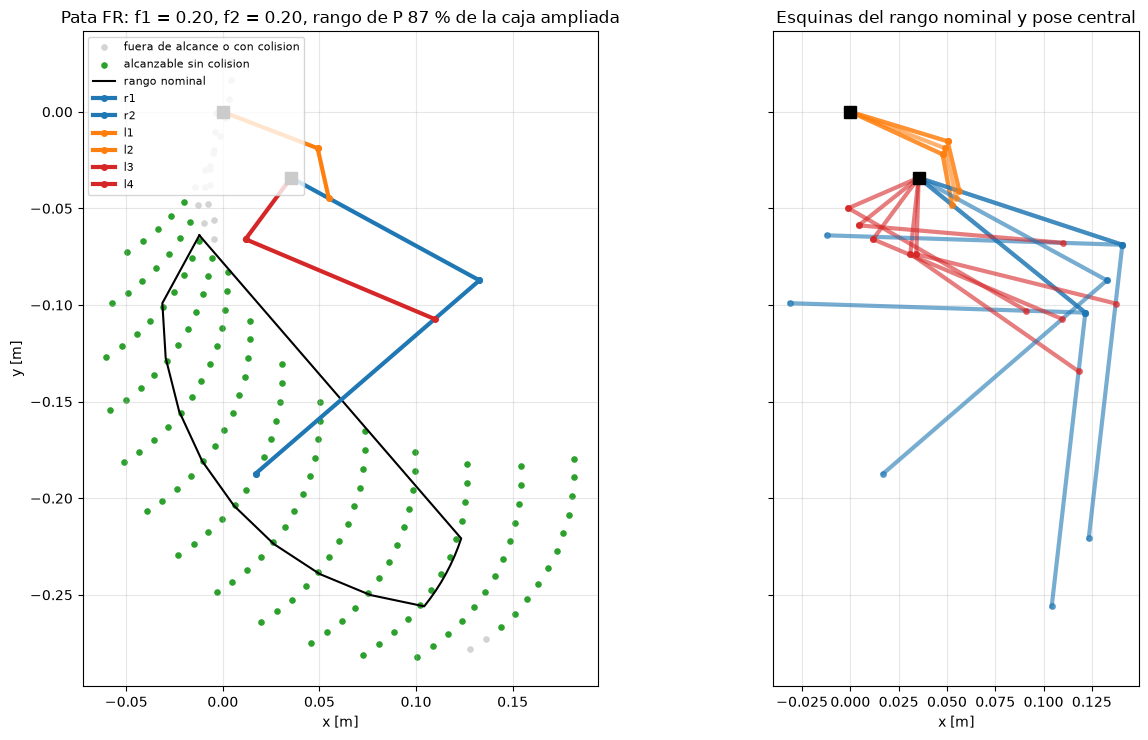

In [9]:
tabla_fr = graficar_diseno(res_fr)

[FR] Trayectoria del CSV: alcanzable 100 %, sin superposicion 100 %


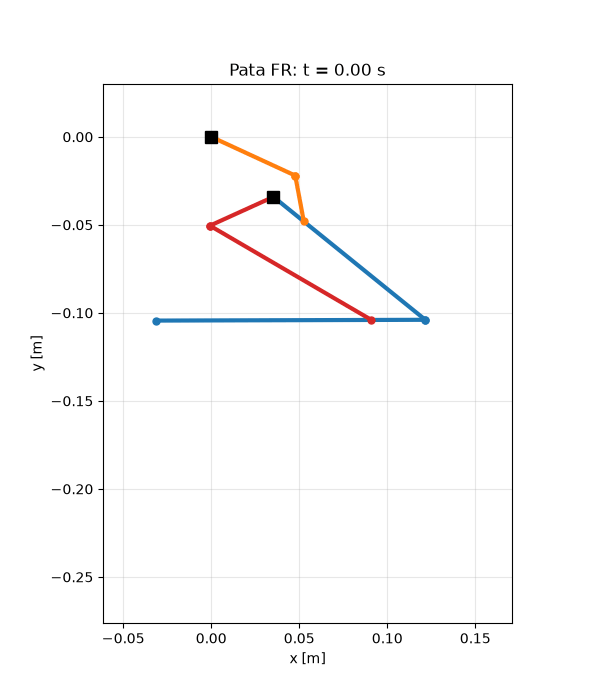

In [10]:
animar(res_fr)

## Pata BR

Longitudes de la pata trasera: `r1 = 0.231` y `r2 = 0.148`, que son el segundo y el tercer eslabón de `paramsrear` en `Mecanismo.ipynb` (tibia y metatarso). Columnas `br_knee_motor` y `br_ankle_motor` del CSV.

Supuestos a revisar: `dx` y `dy` mínimos iguales a los de la pata delantera, y cotas de `l1`-`l3` hasta 400 mm porque los eslabones son más largos.

In [11]:
pt_br = preparar_pata('BR', ('br_knee_motor', 'br_ankle_motor'), R1=0.231, R2=0.148, l_max=0.40)
res_br = optimizar_pata(pt_br)

[BR] Rango nominal  theta1, theta2 [deg]: [[-160.1, -138.5], [-123.0, -69.0]]
[BR] Rango ampliado theta1, theta2 [deg]: [[-180.1, -118.5], [-143.0, -49.0]]


[BR] Barrido terminado en 132 s
[BR] Mejor: f1 = 0.20, f2 = 0.20 | l1 = 49.9, l2 = 30.2, l3 = 232.2, l4 = 42.8 mm | dx = 34.5, dy = 34.5 mm | a3 = -134.6 deg | rango ampliado cubierto 83 %


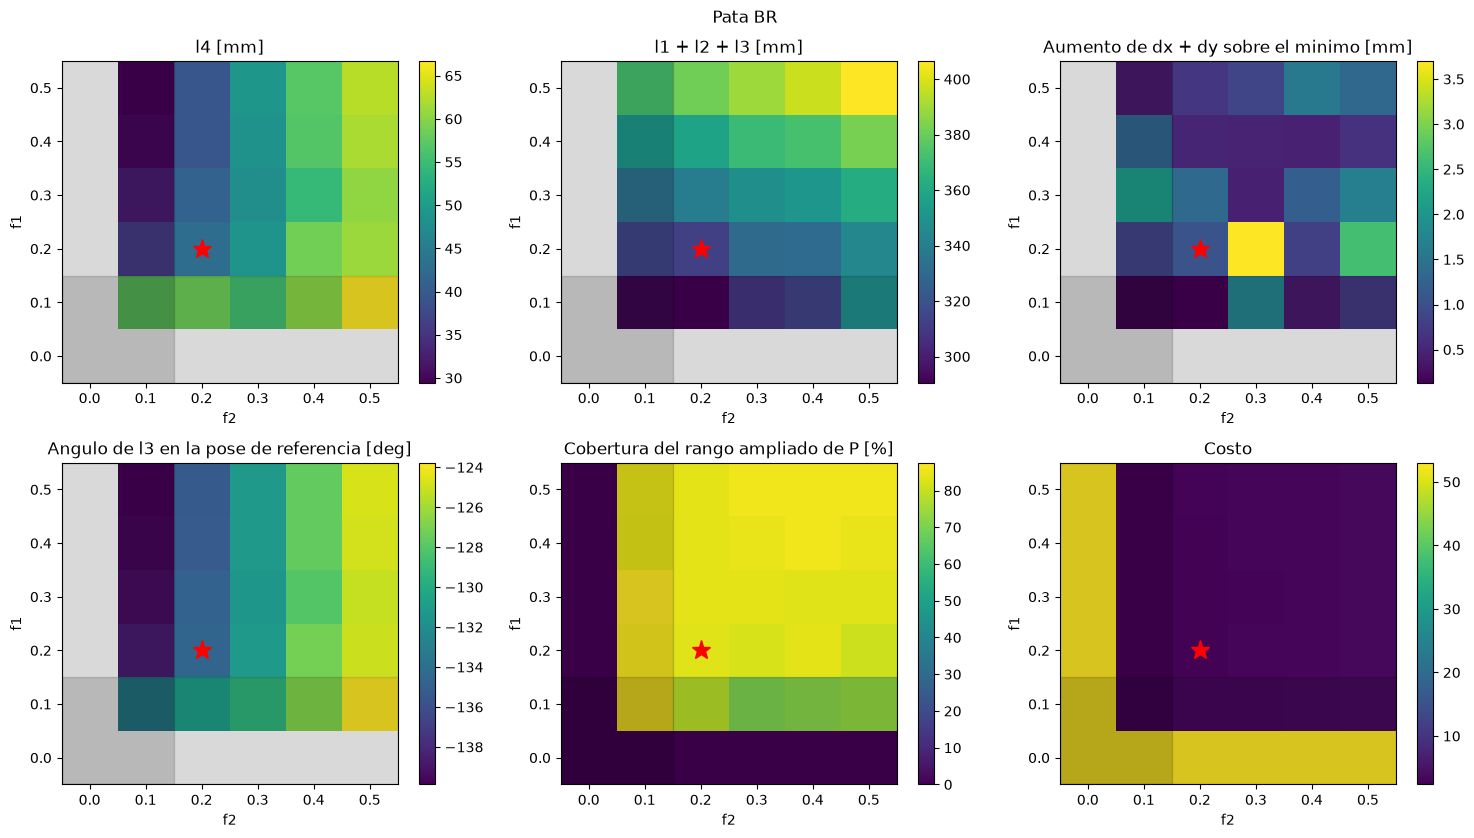

In [12]:
graficar_mapas(res_br)

,pata,eslabon,mecanismo,longitud [m],f,longitud [mm]
0,BR,r1,pata (fijo),0.231000,NaN,231.0
1,BR,r2,pata (fijo),0.148000,NaN,148.0
2,BR,l1,"RR 1, acople en r1",0.049912,0.2,49.9
3,BR,l2,"RR 1, acople en r1",0.030177,0.2,30.2
4,BR,l3,"RR 2, acople en r2 (a -135 deg en la pose de r...",0.232244,0.2,232.2
5,BR,l4,"RR 2, derivado de l3",0.042774,0.2,42.8
6,BR,dx,B -> O en x,0.034462,NaN,34.5
7,BR,dy,B -> O en -y,0.034458,NaN,34.5


[BR] Rango nominal: alcanzable 100 %, sin superposicion 100 %. Rama del codo del RR 1: -1


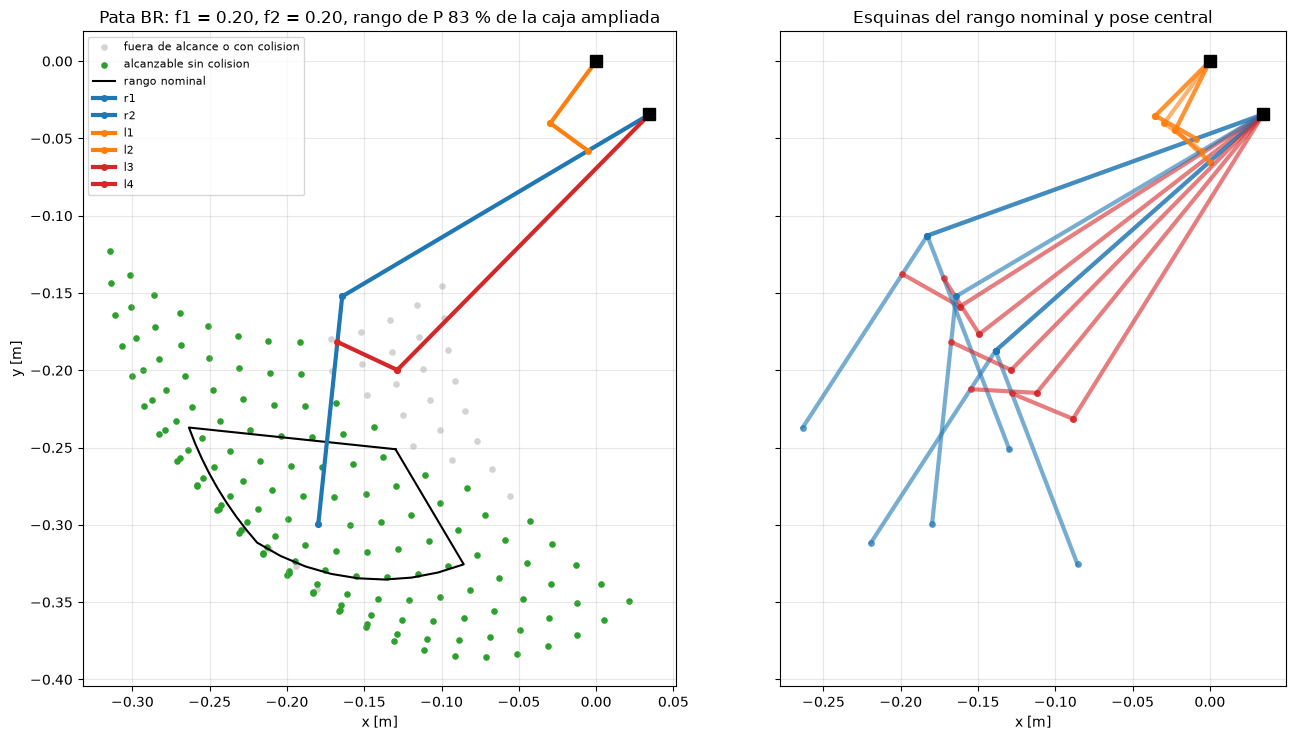

In [13]:
tabla_br = graficar_diseno(res_br)

[BR] Trayectoria del CSV: alcanzable 100 %, sin superposicion 100 %


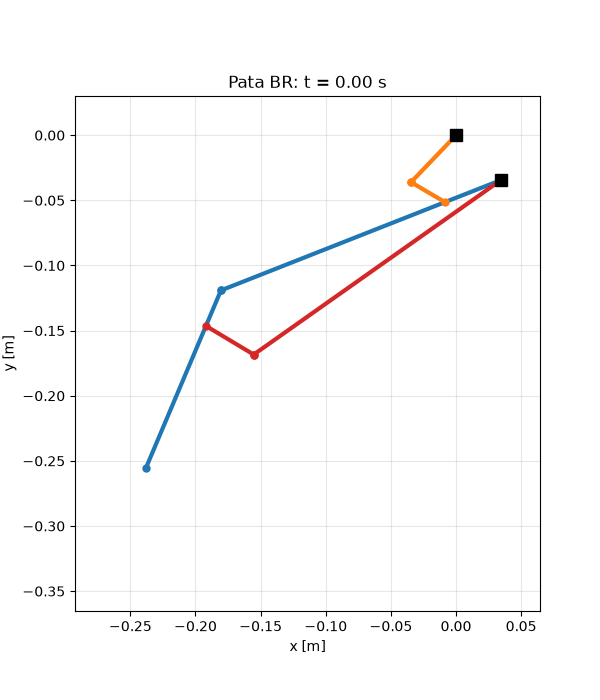

In [14]:
animar(res_br)

## Resumen

Diseño elegido para cada pata.

In [15]:
resumen = pd.DataFrame([
    dict(pata=r['pt']['nombre'], r1=r['pt']['R1'] * 1000, r2=r['pt']['R2'] * 1000, f1=r['f1'], f2=r['f2'],
         l1=r['x'][0] * 1000, l2=r['x'][1] * 1000, l3=r['x'][2] * 1000, l4=r['l4'] * 1000,
         dx=r['x'][3] * 1000, dy=r['x'][4] * 1000, a3_deg=np.degrees(r['x'][5]), rango_P_pct=100 * r['cov_e'])
    for r in (res_fr, res_br)]).set_index('pata').round(1)
print("Longitudes y desplazamientos en mm")
resumen

Longitudes y desplazamientos en mm


,r1,r2,f1,f2,l1,l2,l3,l4,dx,dy,a3_deg,rango_P_pct
pata,,,,,,,,,,,,
FR,111.0,153.0,0.2,0.2,52.6,26.5,39.6,106.3,35.3,34.1,-126.6,87.0
BR,231.0,148.0,0.2,0.2,49.9,30.2,232.2,42.8,34.5,34.5,-134.6,83.4
